# Модели: сравнение, качество, важность признаков

Результаты берутся из таблиц `model_runs`, `predictions`, `feature_importance`, `ablation`, которые заполняет `make train` (последний запуск).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from src.config import load_config

cfg = load_config()
con = duckdb.connect(cfg['paths']['db'], read_only=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.3})
NAMES = {'seasonal_naive': 'Наивный (неделю назад)', 'ridge': 'Ridge', 'lightgbm': 'LightGBM'}
COLORS = {'seasonal_naive': 'tab:gray', 'ridge': 'tab:orange', 'lightgbm': 'tab:blue'}

run_id = con.execute('select max(run_id) from model_runs').fetchone()[0]
runs = con.execute('select * from model_runs where run_id = ?', [run_id]).df()
pred = con.execute('select * from predictions where run_id = ?', [run_id]).df()
pred['date'] = pd.to_datetime(pred['date'])
print('run_id:', run_id, '| версия данных:', runs.data_hash.iloc[0], '| seed:', runs.seed.iloc[0])

run_id: 20261015-165827-ae6d | версия данных: b3ae33bfc6249213 | seed: 42


## 1. Сравнение моделей по единой схеме валидации

In [2]:
cv = runs[runs.stage == 'cv'].groupby('model')[['wape', 'mae', 'rmse']].agg(['mean', 'std'])
hold = runs[runs.stage == 'holdout'].set_index('model')[['wape', 'mae', 'rmse']]
table = pd.DataFrame({
    'CV: WAPE': cv[('wape', 'mean')].map('{:.1%}'.format) + ' ± ' + cv[('wape', 'std')].map('{:.1%}'.format),
    'CV: MAE': cv[('mae', 'mean')].round(1),
    'Отложенная: WAPE': hold['wape'].map('{:.1%}'.format),
    'Отложенная: MAE': hold['mae'].round(1),
    'Отложенная: RMSE': hold['rmse'].round(1),
}).loc[['seasonal_naive', 'ridge', 'lightgbm']].rename(index=NAMES)
table

,CV: WAPE,CV: MAE,Отложенная: WAPE,Отложенная: MAE,Отложенная: RMSE
model,,,,,
Наивный (неделю назад),34.1% ± 13.8%,50.8,24.2%,82.1,302.0
Ridge,19.3% ± 5.2%,31.2,16.2%,54.9,200.8
LightGBM,14.8% ± 2.9%,24.4,13.1%,44.6,162.4


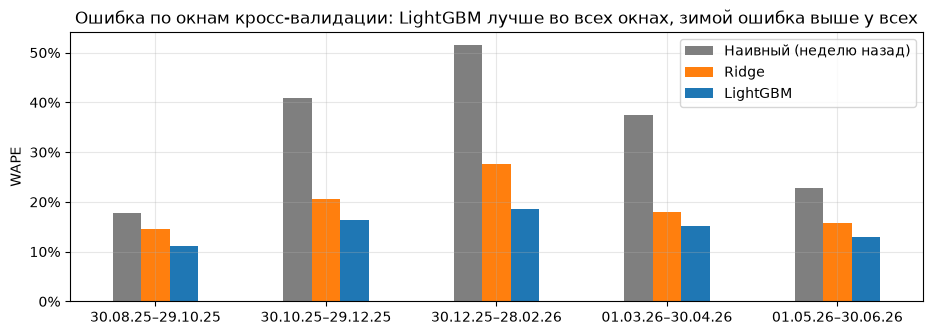

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.5))
f = runs[runs.stage == 'cv'].copy()
f = f.sort_values('valid_start')
f['окно'] = f.valid_start.dt.strftime('%d.%m.%y') + '–' + f.valid_end.dt.strftime('%d.%m.%y')
f.pivot(index='окно', columns='model', values='wape').loc[f['окно'].unique()][['seasonal_naive', 'ridge', 'lightgbm']].rename(columns=NAMES).plot.bar(
    ax=ax, rot=0, color=[COLORS[m] for m in ['seasonal_naive', 'ridge', 'lightgbm']])
ax.legend(title=None); ax.set_xlabel(''); ax.set_ylabel('WAPE'); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Ошибка по окнам кросс-валидации: LightGBM лучше во всех окнах, зимой ошибка выше у всех')
plt.show()

## 2. Факт и прогноз на отложенной выборке (июль–сентябрь 2026)

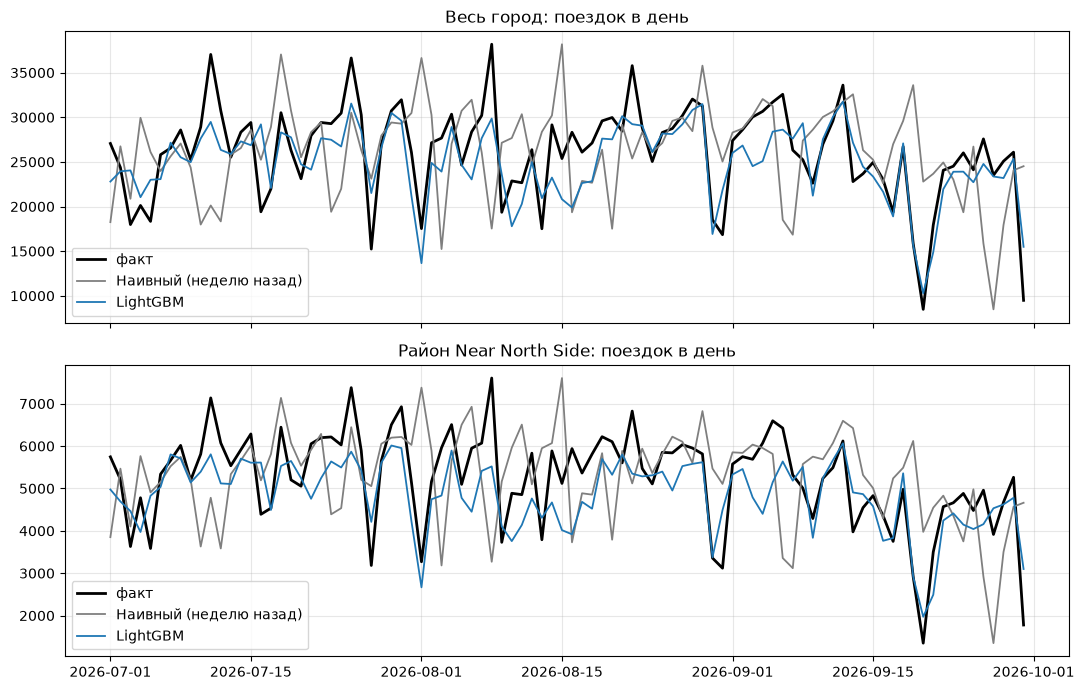

In [4]:
h = pred[pred.stage == 'holdout']
city = h.groupby(['model', 'date'])[['y_true', 'y_pred']].sum().reset_index()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
fact = city[city.model == 'lightgbm']
axes[0].plot(fact.date, fact.y_true, color='black', lw=2, label='факт')
for m in ['seasonal_naive', 'lightgbm']:
    s = city[city.model == m]
    axes[0].plot(s.date, s.y_pred, color=COLORS[m], lw=1.3, label=NAMES[m])
axes[0].set_title('Весь город: поездок в день'); axes[0].legend()

area = 8  # Near North Side — самый загруженный район
a = h[h.area_num == area]
axes[1].plot(a[a.model == 'lightgbm'].date, a[a.model == 'lightgbm'].y_true, color='black', lw=2, label='факт')
for m in ['seasonal_naive', 'lightgbm']:
    s = a[a.model == m]
    axes[1].plot(s.date, s.y_pred, color=COLORS[m], lw=1.3, label=NAMES[m])
axes[1].set_title('Район Near North Side: поездок в день'); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Результат в понятных пользователю величинах

In [5]:
h = h.assign(abs_err=(h.y_true - h.y_pred).abs())
daily = h.groupby(['model', 'date']).agg(y=('y_true', 'sum'), err=('abs_err', 'sum')).reset_index()
s = daily.groupby('model').agg(trips=('y', 'mean'), err=('err', 'mean')).loc[['seasonal_naive', 'ridge', 'lightgbm']]
base = s.loc['seasonal_naive', 'err']
for m, r in s.iterrows():
    print(f"{NAMES[m]:24s}: в среднем за день спрос {r.trips:,.0f} поездок, сумма ошибок по 77 районам {r.err:,.0f} "
          f"({r.err / r.trips:.0%}), лучше наивного на {1 - r.err / base:.0%}")

top = con.execute('select area_num from daily_area group by 1 order by sum(n_trips) desc limit 10').df().area_num
t = h[(h.model == 'lightgbm') & h.area_num.isin(top)]
print(f"\nLightGBM, 10 крупнейших районов: средний спрос {t.y_true.mean():,.0f} поездок в день на район, "
      f"средняя ошибка {t.abs_err.mean():,.0f} поездок ({t.abs_err.sum() / t.y_true.sum():.0%})")

Наивный (неделю назад)  : в среднем за день спрос 26,102 поездок, сумма ошибок по 77 районам 6,325 (24%), лучше наивного на 0%
Ridge                   : в среднем за день спрос 26,102 поездок, сумма ошибок по 77 районам 4,227 (16%), лучше наивного на 33%
LightGBM                : в среднем за день спрос 26,102 поездок, сумма ошибок по 77 районам 3,431 (13%), лучше наивного на 46%

LightGBM, 10 крупнейших районов: средний спрос 2,295 поездок в день на район, средняя ошибка 291 поездок (13%)


## 4. Важность признаков двумя способами и отбор признаков

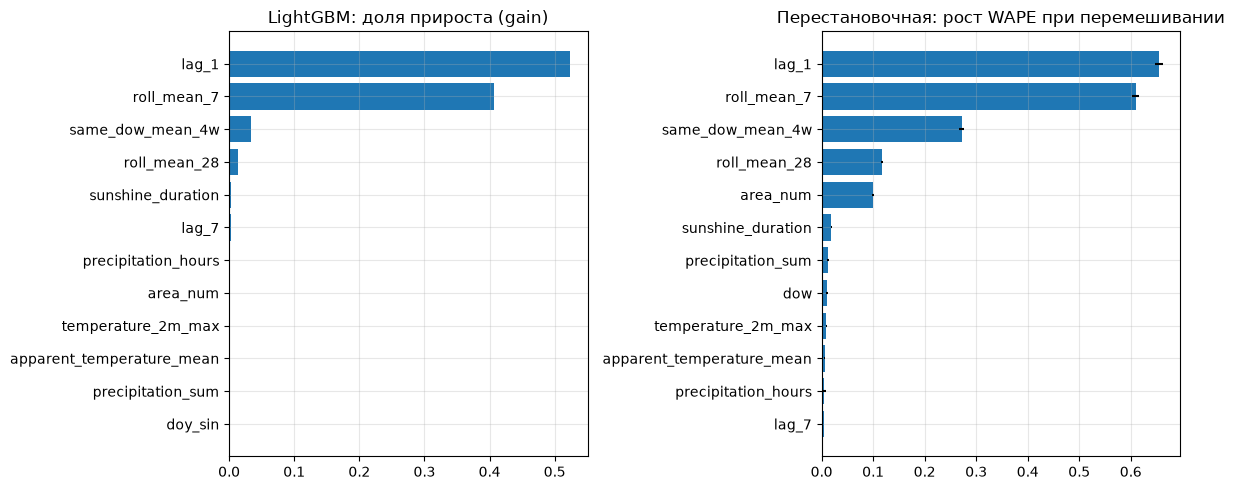

In [6]:
fi = con.execute('select * from feature_importance where run_id = ?', [run_id]).df()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (method, title) in zip(axes, [('lightgbm_gain', 'LightGBM: доля прироста (gain)'),
                                     ('permutation_wape', 'Перестановочная: рост WAPE при перемешивании')]):
    d = fi[fi.method == method].sort_values('importance').tail(12)
    ax.barh(d.feature, d.importance, xerr=d.importance_std if method.startswith('perm') else None, color='tab:blue')
    ax.set_title(title)
plt.tight_layout(); plt.show()

In [7]:
abl = con.execute('select * exclude (run_id) from ablation where run_id = ?', [run_id]).df()
abl['wape'] = abl.wape.map('{:.2%}'.format)
abl['delta_wape'] = (abl.delta_wape * 100).map('{:+.2f} п.п.'.format)
abl.rename(columns={'group': 'набор признаков', 'n_features': 'признаков', 'delta_wape': 'изменение WAPE'})

,набор признаков,признаков,wape,изменение WAPE
0,все признаки,31,12.86%,+0.00 п.п.
1,без lags,24,12.84%,-0.02 п.п.
2,без rolling,27,13.02%,+0.16 п.п.
3,без trip_log,27,13.01%,+0.15 п.п.
4,без calendar,24,13.78%,+0.93 п.п.
5,без weather,23,18.48%,+5.62 п.п.
6,без area,30,14.19%,+1.33 п.п.


## Выводы

1. **Все модели сравнивались по одной схеме:** 5 окон кросс-валидации по 61 дню с расширяющимся обучающим множеством, затем отложенная выборка за июль–сентябрь 2026, которая ни в обучении, ни в выборе модели не участвовала. Метрики: WAPE, MAE, RMSE.
2. **LightGBM лучше во всех окнах.** На отложенной выборке WAPE 13,1% против 16,2% у Ridge и 24,2% у наивного прогноза. Суммарная ошибка по городу за день — 3,4 тыс. поездок вместо 6,3 тыс. у наивного прогноза, то есть **на 46% меньше**. В 10 крупнейших районах ошибка ~290 поездок в день на район при среднем спросе ~2300.
3. **Зимой ошибка выше у всех моделей**, потому что спрос низкий и сильнее зависит от погоды. Наивный прогноз зимой ошибается на 40–50%: погода за неделю успевает сильно поменяться.
4. **Важность признаков.** По обоим способам главные признаки — вчерашний спрос (`lag_1`), среднее за неделю и тот же день недели за 4 прошлые недели. Отдельные погодные признаки выглядят слабыми, но если убрать погоду целиком, WAPE растёт на 5,6 п.п. Причина в том, что погодные признаки дублируют друг друга: перемешивание одного компенсируют остальные. Поэтому важность оценивается и по признакам, и по группам.
5. **Отбор признаков.** Без группы лагов качество не меняется (−0,02 п.п.), потому что эту информацию уже несут окна (`roll_mean_7`). Признаки из журнала поездок дают +0,15 п.п., календарь — +0,9 п.п., район — +1,3 п.п.
